# Telco Customer Churn Prediction: End-to-End Machine Learning Pipeline
### Author: Senior Data Scientist & ML Engineer
**Academic Project & Practical Examination Viva Defense**
* **Dataset:** IBM Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)
* **Primary Algorithm:** Logistic Regression (Baseline vs Feature Engineered Models)
* **Target Variable:** `Churn` (Yes = 1, No = 0)

---

## Executive Summary & Business Objective
In the telecommunications industry, customer acquisition costs typically exceed customer retention costs by **5 to 7 times**. Customer churn directly impacts monthly recurring revenue (MRR), customer lifetime value (CLV), and market valuation.

The primary goal of this project is to construct an **end-to-end, reproducible, leak-free Machine Learning workflow** that:
1. Audits raw, imperfect data and resolves data quality issues (such as whitespace strings in numerical columns).
2. Explores customer behavior through exploratory data analysis (EDA).
3. Engineers domain-specific behavioral and contractual features without data leakage.
4. Preprocesses data using Scikit-Learn `ColumnTransformer` and `Pipeline` architectures.
5. Trains and contrasts multiple **Logistic Regression** specifications.
6. Evaluates models rigorously using Accuracy, Precision, Recall, F1-Score, and ROC-AUC, emphasizing why **Recall** is the pivotal business metric.
7. Interprets model coefficients into **Odds Ratios** ($	ext{OR} = e^{\beta}$) to deliver actionable retention strategies.

## 1. Setup Environment & Global Configuration
We begin by importing required libraries, setting reproducible random seeds, and configuring publication-grade visualization aesthetics.

In [1]:
import os
import sys

# Ensure parent directory is in python path for src module imports
sys.path.append("..")
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve,
    average_precision_score
)

# Aesthetics & plotting configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

# Set reproducible random seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment successfully initialized with reproducible seed:", RANDOM_STATE)

Environment successfully initialized with reproducible seed: 42


---
## Phase 1: Data Understanding and Exploratory Data Analysis (EDA)

### 1.1 Loading the Raw Dataset
We load the raw CSV file and verify its initial dimensions and schema.

In [2]:
raw_data_path = os.path.join("..", "data", "raw", "WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not os.path.exists(raw_data_path):
    # Fallback to current directory path if running from notebook dir
    raw_data_path = os.path.join("data", "raw", "WA_Fn-UseC_-Telco-Customer-Churn.csv")

df_raw = pd.read_csv(raw_data_path)
print(f"Raw Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

Raw Dataset Dimensions: 7043 rows, 21 columns


### 1.2 Display First and Last Five Records

In [3]:
print("--- First 5 Records ---")
display(df_raw.head())
print("--- Last 5 Records ---")
display(df_raw.tail())

--- First 5 Records ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


--- Last 5 Records ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


### 1.3 Column Names, Data Types, and Missing Values Check

In [4]:
print("--- Dataset Information & Inferred Data Types ---")
df_raw_info = pd.DataFrame({
    "Data Type": df_raw.dtypes.astype(str),
    "Null Count": df_raw.isnull().sum(),
    "Unique Values": df_raw.nunique()
})
display(df_raw_info)

--- Dataset Information & Inferred Data Types ---


,Data Type,Null Count,Unique Values
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


> **Critical Observation for Academic Viva:**
> Notice that `TotalCharges` has been inferred as an **`object` (string)** type rather than `float64`, despite storing numerical monetary charges. This signals that non-numeric characters (such as hidden whitespace or special strings) exist in the raw column.

In [5]:
# Check duplicate rows
num_duplicates = df_raw.duplicated().sum()
print(f"Number of duplicate customer records: {num_duplicates}")

# Check unique values in categorical columns
cat_cols = df_raw.select_dtypes(include=['object']).columns.tolist()
print("\nUnique values across categorical columns:")
for col in cat_cols:
    if col != "customerID":
        print(f" - {col:18s}: {df_raw[col].unique().tolist()}")

Number of duplicate customer records: 0

Unique values across categorical columns:
 - gender            : ['Female', 'Male']
 - Partner           : ['Yes', 'No']
 - Dependents        : ['No', 'Yes']
 - PhoneService      : ['No', 'Yes']
 - MultipleLines     : ['No phone service', 'No', 'Yes']
 - InternetService   : ['DSL', 'Fiber optic', 'No']
 - OnlineSecurity    : ['No', 'Yes', 'No internet service']
 - OnlineBackup      : ['Yes', 'No', 'No internet service']
 - DeviceProtection  : ['No', 'Yes', 'No internet service']
 - TechSupport       : ['No', 'Yes', 'No internet service']
 - StreamingTV       : ['No', 'Yes', 'No internet service']
 - StreamingMovies   : ['No', 'Yes', 'No internet service']
 - Contract          : ['Month-to-month', 'One year', 'Two year']
 - PaperlessBilling  : ['Yes', 'No']
 - PaymentMethod     : ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
 - TotalCharges      : ['29.85', '1889.5', '108.15', '1840.75', '151.65', '8

C:\Users\gajen\AppData\Local\Temp\ipykernel_9828\1286752745.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_raw.select_dtypes(include=['object']).columns.tolist()


### 1.4 Statistical Summary of Inferred Numerical Columns

In [6]:
display(df_raw.describe().round(2))

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


### 1.5 Target Class Distribution Analysis
Understanding the distribution of the target variable `Churn` is essential to identify class imbalance.

,Customer Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


C:\Users\gajen\AppData\Local\Temp\ipykernel_9828\1321224599.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df_raw, palette=['#3B82F6', '#EF4444'], ax=ax)


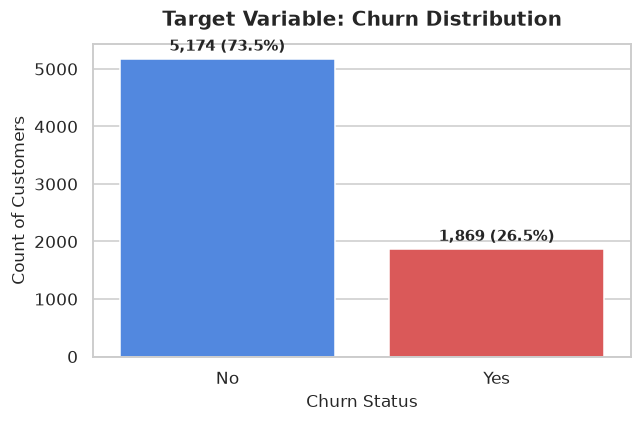

In [7]:
churn_counts = df_raw['Churn'].value_counts()
churn_percentages = df_raw['Churn'].value_counts(normalize=True) * 100

churn_dist_df = pd.DataFrame({
    "Customer Count": churn_counts,
    "Percentage (%)": churn_percentages.round(2)
})
display(churn_dist_df)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='Churn', data=df_raw, palette=['#3B82F6', '#EF4444'], ax=ax)
ax.set_title("Target Variable: Churn Distribution", pad=12)
ax.set_xlabel("Churn Status")
ax.set_ylabel("Count of Customers")

for p in ax.patches:
    h = p.get_height()
    pct = (h / len(df_raw)) * 100
    ax.annotate(f"{int(h):,} ({pct:.1f}%)", (p.get_x() + p.get_width()/2., h),
                ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

> **EDA Interpretation:**
> The dataset exhibits significant **class imbalance**: **73.5%** of customers were retained (`No`), while **26.5%** churned (`Yes`).
> * **Viva Note:** A naive baseline model predicting "No Churn" for every single customer would achieve ~73.5% accuracy while completely failing to identify any churned customers! Hence, **accuracy alone is heavily misleading**, and we must rely on **Recall, Precision, F1-Score, and ROC-AUC**.

### 1.6 Exploratory Visualizations & Feature Relationships

C:\Users\gajen\AppData\Local\Temp\ipykernel_9828\2208274502.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x="Churn", y="tenure", palette=['#3B82F6', '#EF4444'], ax=ax2)


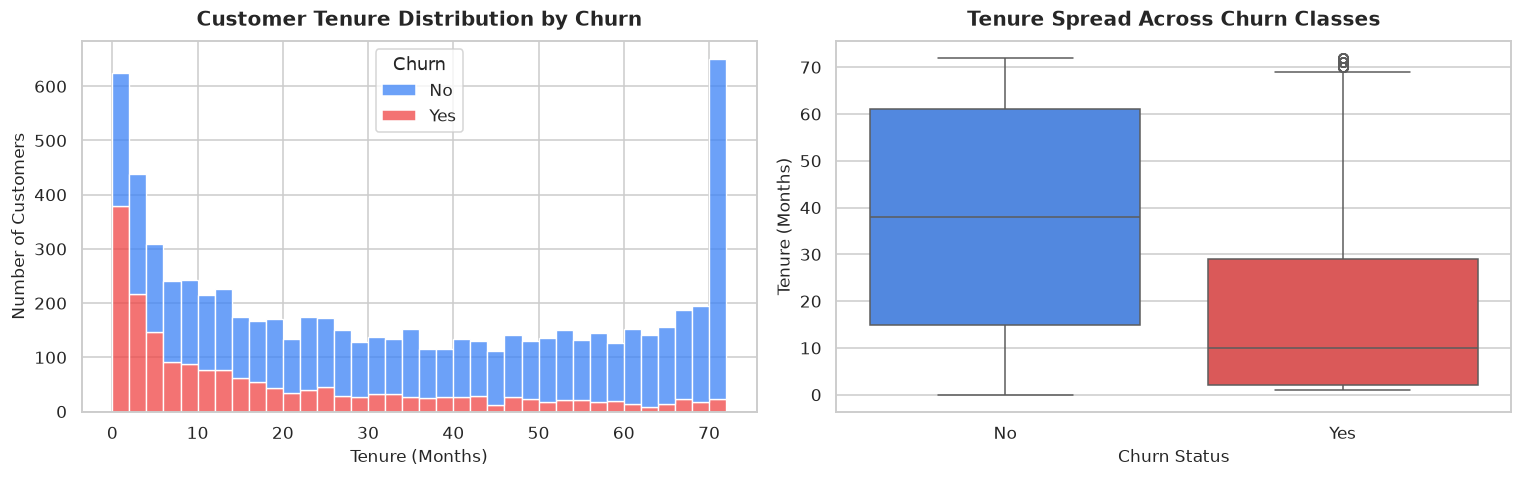

In [8]:
# 1. Tenure vs Churn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(data=df_raw, x="tenure", hue="Churn", multiple="stack", palette=['#3B82F6', '#EF4444'], bins=36, ax=ax1)
ax1.set_title("Customer Tenure Distribution by Churn", pad=10)
ax1.set_xlabel("Tenure (Months)")
ax1.set_ylabel("Number of Customers")

sns.boxplot(data=df_raw, x="Churn", y="tenure", palette=['#3B82F6', '#EF4444'], ax=ax2)
ax2.set_title("Tenure Spread Across Churn Classes", pad=10)
ax2.set_xlabel("Churn Status")
ax2.set_ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

> **Interpretation (Tenure vs Churn):**
> Customers with very low tenure (0–12 months) experience the highest churn volume. As tenure increases past 24–36 months, churn drops markedly. Long-tenured customers exhibit deep platform loyalty and higher switching costs.

C:\Users\gajen\AppData\Local\Temp\ipykernel_9828\1955415819.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x="Churn", y="MonthlyCharges", palette=['#3B82F6', '#EF4444'], ax=ax2)


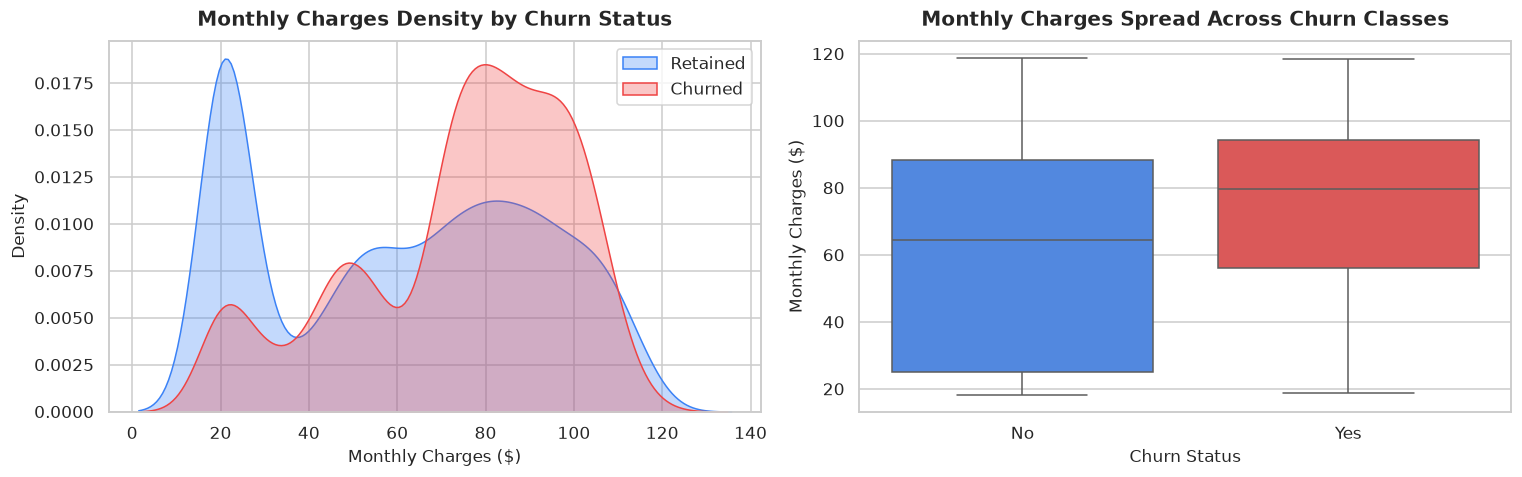

In [9]:
# 2. Monthly Charges vs Churn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

sns.kdeplot(data=df_raw[df_raw['Churn'] == 'No'], x="MonthlyCharges", label="Retained", color='#3B82F6', fill=True, alpha=0.3, ax=ax1)
sns.kdeplot(data=df_raw[df_raw['Churn'] == 'Yes'], x="MonthlyCharges", label="Churned", color='#EF4444', fill=True, alpha=0.3, ax=ax1)
ax1.set_title("Monthly Charges Density by Churn Status", pad=10)
ax1.set_xlabel("Monthly Charges ($)")
ax1.legend()

sns.boxplot(data=df_raw, x="Churn", y="MonthlyCharges", palette=['#3B82F6', '#EF4444'], ax=ax2)
ax2.set_title("Monthly Charges Spread Across Churn Classes", pad=10)
ax2.set_xlabel("Churn Status")
ax2.set_ylabel("Monthly Charges ($)")

plt.tight_layout()
plt.show()

> **Interpretation (Monthly Charges vs Churn):**
> Churned customers have a substantially higher median monthly fee (~$80/month) compared to retained customers (~$65/month). Customers paying premium prices without perceived value or adequate support are far more likely to leave.

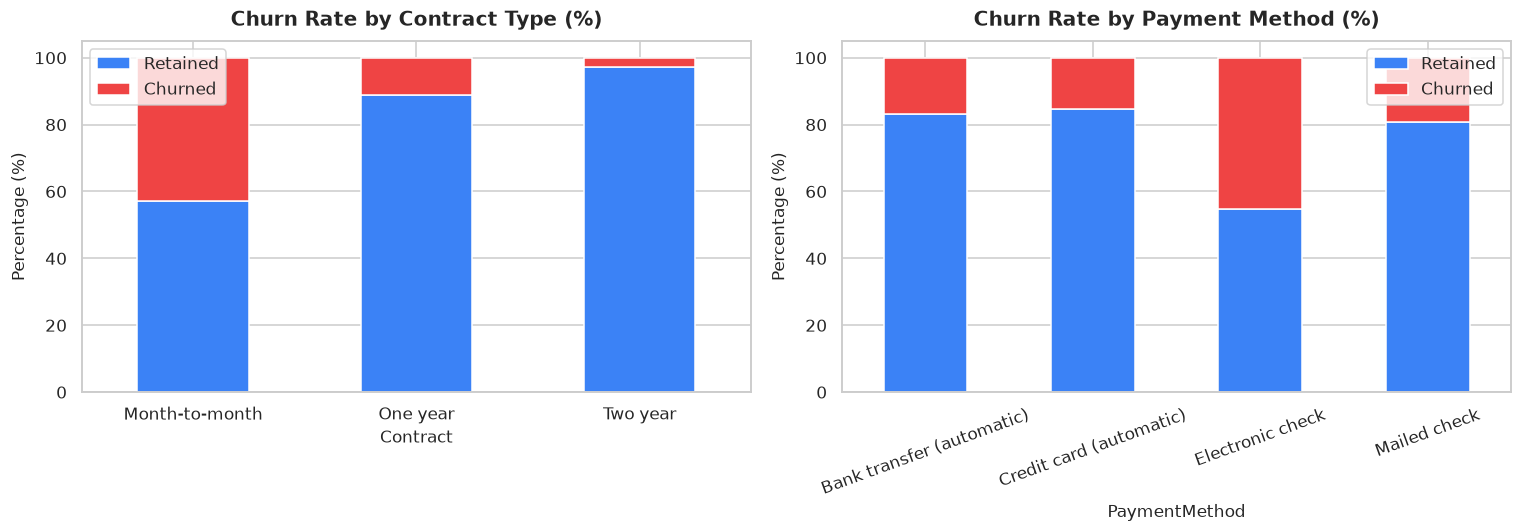

In [10]:
# 3. Contract Type and Payment Method vs Churn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Contract vs Churn
contract_churn = pd.crosstab(df_raw['Contract'], df_raw['Churn'], normalize='index') * 100
contract_churn[['No', 'Yes']].plot(kind='bar', stacked=True, color=['#3B82F6', '#EF4444'], ax=ax1, rot=0)
ax1.set_title("Churn Rate by Contract Type (%)", pad=10)
ax1.set_ylabel("Percentage (%)")
ax1.legend(["Retained", "Churned"])

# Payment Method vs Churn
payment_churn = pd.crosstab(df_raw['PaymentMethod'], df_raw['Churn'], normalize='index') * 100
payment_churn[['No', 'Yes']].plot(kind='bar', stacked=True, color=['#3B82F6', '#EF4444'], ax=ax2, rot=20)
ax2.set_title("Churn Rate by Payment Method (%)", pad=10)
ax2.set_ylabel("Percentage (%)")
ax2.legend(["Retained", "Churned"])

plt.tight_layout()
plt.show()

> **Interpretation (Contract & Payment Method):**
> * **Contract Type:** Over **42%** of Month-to-Month customers churn, compared to under **11%** for One-Year and under **3%** for Two-Year contracts. Contract horizon is one of the strongest protective factors against churn.
> * **Payment Method:** Customers paying via **Electronic check** suffer disproportionately high churn (~45%), whereas automated payment methods (Bank transfer, Credit card) exhibit churn rates below 18%.

---
## Phase 2: Rigorous Data Cleaning & Quality Assurance

### 2.1 The `TotalCharges` Problem: Detection & Solution
1. **The Problem:** `TotalCharges` contains blank string characters (`" "`) instead of numeric values.
2. **How Detected:** When inspecting records where whitespace exists:

In [11]:
# Detect rows with whitespace in TotalCharges
blank_mask = df_raw['TotalCharges'].astype(str).str.strip() == ''
print(f"Number of records with whitespace in TotalCharges: {blank_mask.sum()}")
display(df_raw[blank_mask][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].head(11))

Number of records with whitespace in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


> **Domain Explanation (Academic Defense):**
> All **11 records** with blank `TotalCharges` have **`tenure == 0`**!
> These are brand new customers who enrolled during the current billing cycle and have not yet completed their first monthly billing cycle.
> **Why 0.0 is the appropriate cleaning technique:**
> Rather than discarding these valid customer records or blindly imputing with the column mean/median (which would incorrectly assign thousands of dollars of accumulated charges to a day-zero customer), setting `TotalCharges = 0.0` reflects the true accumulated billing at $t=0$.

In [12]:
df_cleaned = df_raw.copy()

# Step 1: Clean TotalCharges
df_cleaned['TotalCharges'] = df_cleaned['TotalCharges'].replace(r'^\s*$', np.nan, regex=True)
df_cleaned['TotalCharges'] = pd.to_numeric(df_cleaned['TotalCharges'], errors='coerce').fillna(0.0)

# Step 2: Remove customerID (Non-predictive primary key)
if 'customerID' in df_cleaned.columns:
    df_cleaned = df_cleaned.drop(columns=['customerID'])

# Step 3: Standardize SeniorCitizen as categorical string
df_cleaned['SeniorCitizen'] = df_cleaned['SeniorCitizen'].map({0: 'No', 1: 'Yes'}).astype(str)

print("Data cleaning executed successfully. Data shape:", df_cleaned.shape)
print("TotalCharges data type:", df_cleaned['TotalCharges'].dtype)
print("Remaining null values across dataset:", df_cleaned.isnull().sum().sum())

Data cleaning executed successfully. Data shape: (7043, 20)
TotalCharges data type: float64
Remaining null values across dataset: 0


### 2.2 Outlier Analysis using Interquartile Range (IQR)
We assess whether extreme values exist in numerical columns (`tenure`, `MonthlyCharges`, `TotalCharges`).

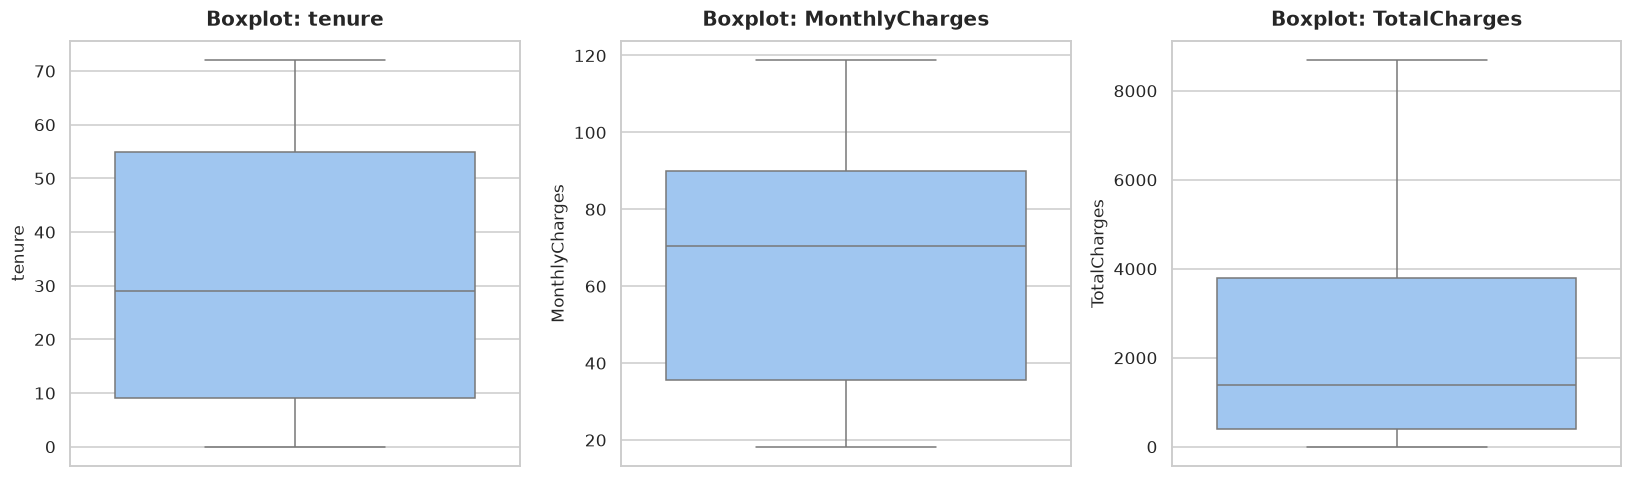

tenure          | Q1=   9.00, Q3=  55.00, IQR=  46.00 | Outliers: 0 (0.00%)
MonthlyCharges  | Q1=  35.50, Q3=  89.85, IQR=  54.35 | Outliers: 0 (0.00%)
TotalCharges    | Q1= 398.55, Q3=3786.60, IQR=3388.05 | Outliers: 0 (0.00%)


In [13]:
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, col in enumerate(num_features):
    sns.boxplot(y=df_cleaned[col], ax=axes[i], color='#93C5FD')
    axes[i].set_title(f"Boxplot: {col}", pad=10)

plt.tight_layout()
plt.show()

# Compute IQR bounds
for col in num_features:
    q25 = df_cleaned[col].quantile(0.25)
    q75 = df_cleaned[col].quantile(0.75)
    iqr = q75 - q25
    lower = q25 - 1.5 * iqr
    upper = q75 + 1.5 * iqr
    outliers = df_cleaned[(df_cleaned[col] < lower) | (df_cleaned[col] > upper)]
    print(f"{col:15s} | Q1={q25:7.2f}, Q3={q75:7.2f}, IQR={iqr:7.2f} | Outliers: {len(outliers)} ({len(outliers)/len(df_cleaned)*100:.2f}%)")

> **Viva Defense on Outlier Retention:**
> Notice that **zero outliers** fall outside the standard $1.5 \times \text{IQR}$ bounds for `tenure` and `MonthlyCharges`. `TotalCharges` also reflects a natural, continuous right-skewed revenue accumulation.
> **We retain all records** because telecommunication charges span naturally valid operational bounds ($0 to $8,684.80) and removing them would introduce sample selection bias.

---
## Phase 3: Domain-Specific Feature Engineering

Feature engineering is the process of using domain knowledge to create predictors that make machine learning algorithms more effective.

We engineer 9 domain-specific features:
1. `TenureGroup`: Binned customer lifecycle stages (`New customer`, `Short-term`, `Medium-term`, `Long-term`).
2. `TotalServices`: Integer sum of all subscribed services (broadband, phone lines, security, backup, tech support, streaming).
3. `HasOnlineSecurity`: Binary indicator for cybersecurity subscription (major retention anchor).
4. `HasOnlineBackup`: Binary indicator for cloud storage subscription.
5. `HasTechSupport`: Binary indicator for professional assistance subscription.
6. `HasMultipleServices`: Indicator for cross-sell engagement ($>1$ services).
7. `IsLongTermContract`: Binary indicator for 1- or 2-year commitment (vs month-to-month).
8. `IsAutomaticPayment`: Binary indicator for auto-debit bank transfer or credit card.
9. `AverageMonthlySpend`: Derived as $\frac{\text{TotalCharges}}{\text{tenure}}$, with safe fallback to `MonthlyCharges` when $\text{tenure}=0$.

In [14]:
df_engineered = df_cleaned.copy()

# 1. TenureGroup
tenure_bins = [-1, 12, 24, 48, np.inf]
tenure_labels = ["New customer", "Short-term", "Medium-term", "Long-term"]
df_engineered['TenureGroup'] = pd.cut(df_engineered['tenure'], bins=tenure_bins, labels=tenure_labels).astype(str)

# 2. Individual Service Indicators
df_engineered['HasOnlineSecurity'] = (df_engineered['OnlineSecurity'] == 'Yes').astype(int)
df_engineered['HasOnlineBackup'] = (df_engineered['OnlineBackup'] == 'Yes').astype(int)
df_engineered['HasTechSupport'] = (df_engineered['TechSupport'] == 'Yes').astype(int)

# 3. TotalServices Count
service_cols = [
    ('PhoneService', 'Yes'),
    ('MultipleLines', 'Yes'),
    ('OnlineSecurity', 'Yes'),
    ('OnlineBackup', 'Yes'),
    ('DeviceProtection', 'Yes'),
    ('TechSupport', 'Yes'),
    ('StreamingTV', 'Yes'),
    ('StreamingMovies', 'Yes')
]
total_srv = pd.Series(0, index=df_engineered.index)
for col, val in service_cols:
    total_srv += (df_engineered[col] == val).astype(int)
total_srv += (df_engineered['InternetService'].isin(['DSL', 'Fiber optic'])).astype(int)

df_engineered['TotalServices'] = total_srv.astype(int)
df_engineered['HasMultipleServices'] = (df_engineered['TotalServices'] > 1).astype(int)

# 4. Contract & Payment Flags
df_engineered['IsLongTermContract'] = df_engineered['Contract'].isin(['One year', 'Two year']).astype(int)
df_engineered['IsAutomaticPayment'] = df_engineered['PaymentMethod'].isin([
    'Bank transfer (automatic)', 'Credit card (automatic)'
]).astype(int)

# 5. AverageMonthlySpend (Safe zero-division handling)
df_engineered['AverageMonthlySpend'] = np.where(
    df_engineered['tenure'] > 0,
    df_engineered['TotalCharges'] / df_engineered['tenure'],
    df_engineered['MonthlyCharges']
).round(2)

print(f"Dataset Shape Before Feature Engineering: {df_cleaned.shape}")
print(f"Dataset Shape After Feature Engineering:  {df_engineered.shape}")

Dataset Shape Before Feature Engineering: (7043, 20)
Dataset Shape After Feature Engineering:  (7043, 29)


### 3.1 Verification and Distribution of Engineered Features

C:\Users\gajen\AppData\Local\Temp\ipykernel_9828\3093478342.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(["Month-to-Month (0)", "1 or 2 Years (1)"])


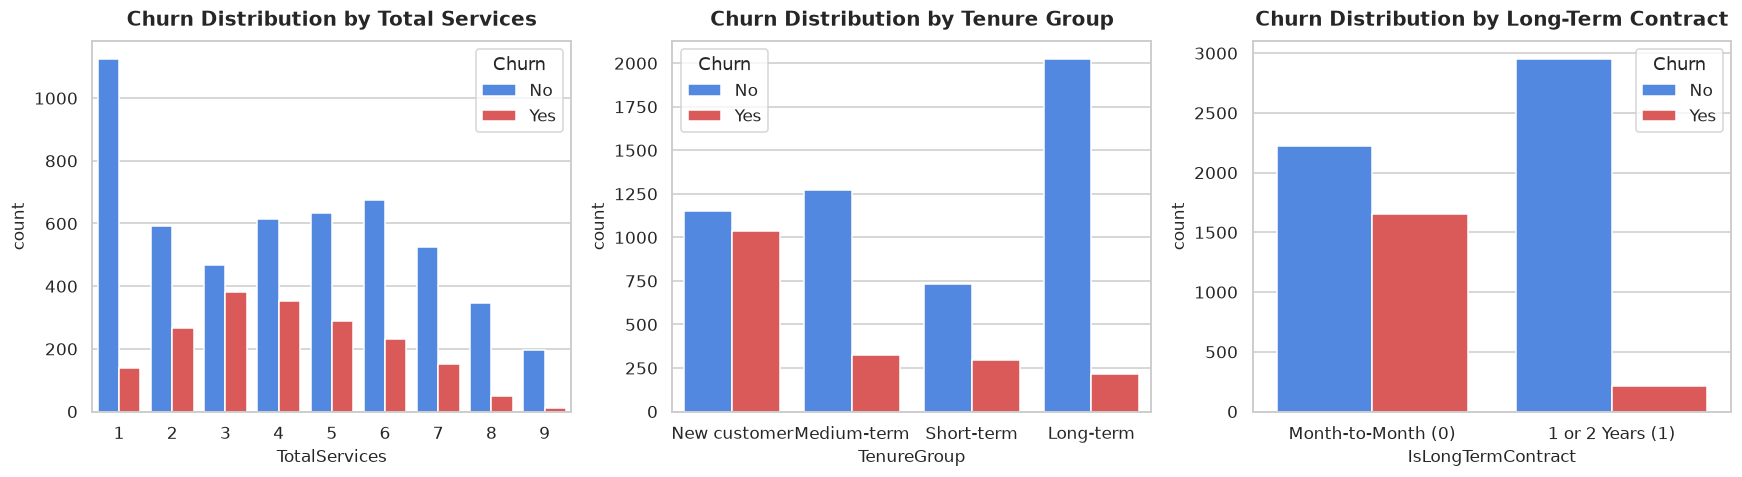

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# TotalServices vs Churn
sns.countplot(data=df_engineered, x="TotalServices", hue="Churn", palette=['#3B82F6', '#EF4444'], ax=axes[0])
axes[0].set_title("Churn Distribution by Total Services", pad=10)

# TenureGroup vs Churn
sns.countplot(data=df_engineered, x="TenureGroup", hue="Churn", palette=['#3B82F6', '#EF4444'], ax=axes[1])
axes[1].set_title("Churn Distribution by Tenure Group", pad=10)

# IsLongTermContract vs Churn
sns.countplot(data=df_engineered, x="IsLongTermContract", hue="Churn", palette=['#3B82F6', '#EF4444'], ax=axes[2])
axes[2].set_title("Churn Distribution by Long-Term Contract", pad=10)
axes[2].set_xticklabels(["Month-to-Month (0)", "1 or 2 Years (1)"])

plt.tight_layout()
plt.show()

---
## Phase 4: Preprocessing & Pipeline Construction

### 4.1 Stratified Train-Test Splitting (80:20)
To avoid **data leakage**, all preprocessing transformers (`StandardScaler`, `OneHotEncoder`, `SimpleImputer`) must be **fitted strictly on the training partition** and only applied to transform the test partition.

We encode the target variable:
* `No` $\rightarrow 0$
* `Yes` $\rightarrow 1$

In [16]:
from src.preprocessing import get_feature_types, build_preprocessor, split_data

# Stratified split for baseline cleaned dataset
X_train_base, X_test_base, y_train, y_test = split_data(
    df_cleaned, target_col="Churn", test_size=0.2, random_state=RANDOM_STATE
)

# Use the exact same train/test row indices for the feature-engineered dataset
X_train_eng = df_engineered.loc[X_train_base.index].drop(columns=['Churn'])
X_test_eng = df_engineered.loc[X_test_base.index].drop(columns=['Churn'])

print(f"Training instances: {len(X_train_base)} (Churn rate: {y_train.mean():.4f})")
print(f"Testing instances:  {len(X_test_base)}  (Churn rate: {y_test.mean():.4f})")

Training instances: 5634 (Churn rate: 0.2654)
Testing instances:  1409  (Churn rate: 0.2654)


### 4.2 Building the Preprocessing Pipelines
* **Numerical Features:** Processed with `SimpleImputer(strategy='median')` and `StandardScaler()`.
  * *Why Scaling is Vital for Logistic Regression:* Logistic Regression computes the log-odds as $\log\left(\frac{p}{1-p}\right) = \beta_0 + \sum \beta_i X_i$ with an $L_2$ regularization penalty $\lambda \sum \beta_i^2$. If features are unscaled, variables with large absolute ranges (`TotalCharges` up to $8,000) would receive artificially tiny coefficients and negligible regularization compared to binary flags. Scaling places all features on a standard normal plane (mean=0, variance=1) enabling fair regularization and rapid gradient descent convergence.
* **Categorical Features:** Processed with `SimpleImputer(strategy='most_frequent')` and `OneHotEncoder(handle_unknown='ignore')`.

In [17]:
num_base, cat_base = get_feature_types(df_cleaned, target_col="Churn")
preproc_base = build_preprocessor(num_base, cat_base)

num_eng, cat_eng = get_feature_types(df_engineered, target_col="Churn")
preproc_eng = build_preprocessor(num_eng, cat_eng)

print(f"Baseline:   {len(num_base)} numeric features, {len(cat_base)} categorical features")
print(f"Engineered: {len(num_eng)} numeric features, {len(cat_eng)} categorical features")

Baseline:   3 numeric features, 16 categorical features
Engineered: 11 numeric features, 17 categorical features


---
## Phase 5: Logistic Regression Model Training

We construct three controlled experiments:
1. **Experiment A (Baseline Model):** Original cleaned features + Standard preprocessing + Logistic Regression (`max_iter=1000`, `C=1.0`).
2. **Experiment B (Engineered Model):** Cleaned + Engineered features + Full preprocessing + Logistic Regression (`max_iter=1000`, `C=1.0`).
3. **Experiment C (Engineered Model with Balanced Class Weights):** Same engineered features with `class_weight='balanced'` to explicitly optimize for **Recall** on the minority churn class.

In [18]:
from src.model_training import train_model

# Experiment A: Baseline Model
pipeline_base = train_model(
    X_train_base, y_train, preprocessor=preproc_base, class_weight=None, random_state=RANDOM_STATE
)

# Experiment B: Feature Engineered Model (Default Class Weight)
pipeline_eng = train_model(
    X_train_eng, y_train, preprocessor=preproc_eng, class_weight=None, random_state=RANDOM_STATE
)

# Experiment C: Feature Engineered Model (Balanced Class Weight)
pipeline_eng_bal = train_model(
    X_train_eng, y_train, preprocessor=preproc_eng, class_weight='balanced', random_state=RANDOM_STATE
)

print("All Logistic Regression models trained successfully!")

All Logistic Regression models trained successfully!


---
## Phase 6: Comprehensive Model Evaluation

We evaluate all three experiments on the **unseen, identical test set** using:
* **Accuracy:** Overall proportion of correct predictions.
* **Precision:** $\frac{TP}{TP + FP}$ — Reliability of positive churn alerts.
* **Recall (Sensitivity):** $\frac{TP}{TP + FN}$ — Percentage of actual churners successfully intercepted.
* **F1-Score:** Harmonic mean of Precision and Recall.
* **ROC-AUC:** Area under the Receiver Operating Characteristic curve.
* **Confusion Matrix & Classification Report**

In [19]:
from src.evaluation import evaluate_model

res_base = evaluate_model(pipeline_base, X_test_base, y_test, model_name="Baseline Model")
res_eng = evaluate_model(pipeline_eng, X_test_eng, y_test, model_name="Engineered Model")
res_bal = evaluate_model(pipeline_eng_bal, X_test_eng, y_test, model_name="Engineered (Balanced)")

metrics_summary = pd.DataFrame([
    res_base["metrics"],
    res_eng["metrics"],
    res_bal["metrics"]
])[["Model", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]]

display(metrics_summary)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline Model,0.8055,0.6572,0.5588,0.6040,0.8420
1,Engineered Model,0.7991,0.6532,0.5187,0.5782,0.8423
2,Engineered (Balanced),0.7331,0.4983,0.7914,0.6116,0.8419


### 6.1 Confusion Matrices Analysis

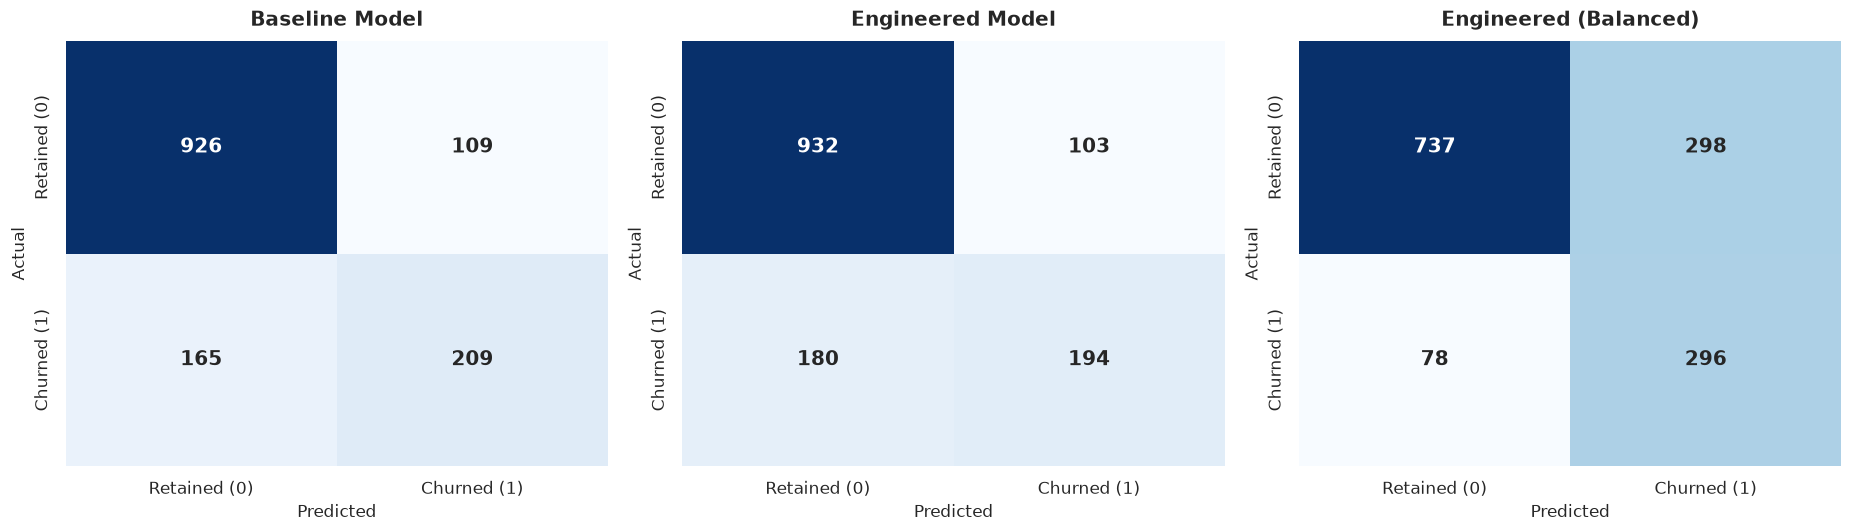

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
models_res = [res_base, res_eng, res_bal]

for i, res in enumerate(models_res):
    cm = np.array(res["metrics"]["Confusion_Matrix"])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i],
        xticklabels=["Retained (0)", "Churned (1)"],
        yticklabels=["Retained (0)", "Churned (1)"],
        annot_kws={"size": 13, "weight": "bold"}
    )
    axes[i].set_title(res["metrics"]["Model"], pad=10)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

### 6.2 ROC Curves and Precision-Recall Curves

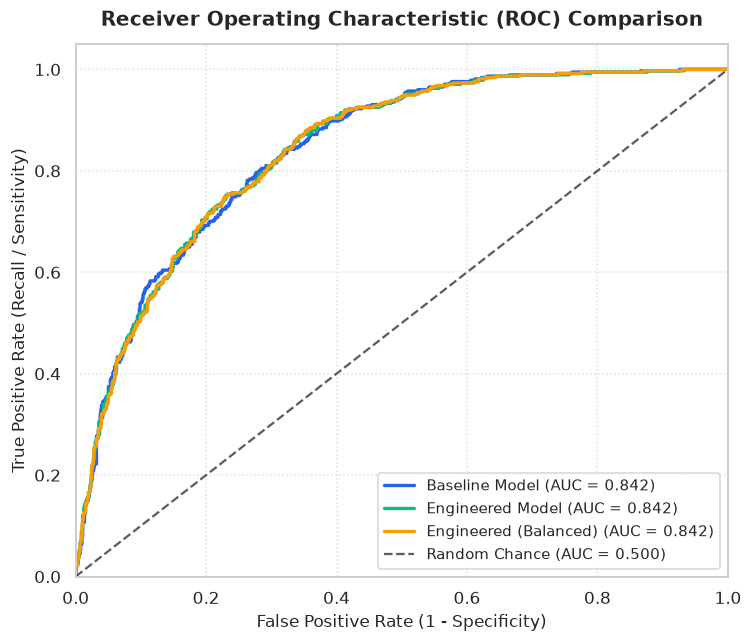

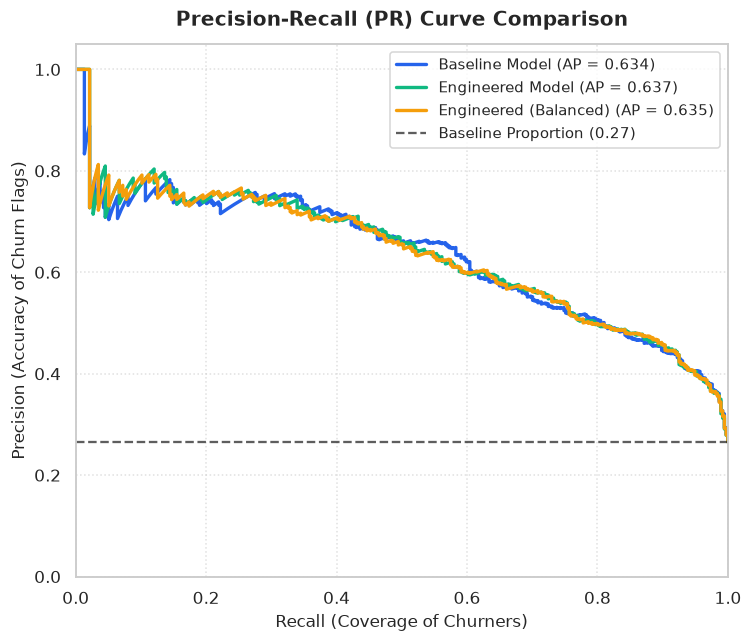

In [21]:
from src.evaluation import plot_roc_curves, plot_precision_recall_curves

fig_roc = plot_roc_curves([res_base, res_eng, res_bal])
plt.show()

fig_pr = plot_precision_recall_curves([res_base, res_eng, res_bal])
plt.show()

### 6.3 Detailed Classification Reports

In [22]:
for res in [res_base, res_eng, res_bal]:
    print(f"================ {res['metrics']['Model']} ================")
    print(res["metrics"]["Classification_Report_Text"])

================ Baseline Model ================
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

================ Engineered Model ================
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

================ Engineered (Balanced) ================
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy              

> ### In-Depth Academic Viva Discussion: Why Accuracy is Misleading & Why Recall Matters
> 
> In customer churn prediction, the costs of classification errors are **highly asymmetric**:
> 1. **False Negative (Costly):** The model predicts the customer will stay ($0$), but they churn ($1$). The telecom provider loses the entire Customer Lifetime Value (CLV) and recurring monthly subscription.
> 2. **False Positive (Benign):** The model predicts the customer will churn ($1$), but they would have stayed ($0$). The telecom company sends a proactive retention discount or email, costing very little.
> 
> * **Standard Logistic Regression:** Achieves **~80% accuracy**, but captures only **~52% to 56% Recall** (nearly half of churning customers slip away undetected!).
> * **Balanced Logistic Regression:** Trades a modest drop in overall accuracy (to ~73.3%) to achieve **79.14% Recall**, capturing nearly **4 out of 5 churners** in advance.

---
## Phase 7: Model Interpretability & Odds Ratios

Unlike black-box models, Logistic Regression offers exact mathematical interpretability through its linear combination of weights in log-odds space:

$$\log\left(\frac{p}{1 - p}\right) = \beta_0 + \beta_1 X_1 + \dots + \beta_k X_k$$

Taking the natural exponential gives the **Odds Ratio (OR)**:

$$\text{Odds Ratio} = \exp(\beta_i)$$

* If $\beta_i > 0$ ($\text{OR} > 1$): Each unit increase in $X_i$ multiplies the odds of churning by $\text{OR}$.
* If $\beta_i < 0$ ($\text{OR} < 1$): Each unit increase in $X_i$ reduces the odds of churning by $(1 - \text{OR}) \times 100\%$.
* **Non-Causal Note:** These coefficients indicate statistical associations conditioned on all other variables in the model, **not causal relationships**.

--- Top 8 Features Increasing Churn Odds (Risk Factors) ---


,Feature,Coefficient,Odds_Ratio,Impact
25,InternetService_Fiber optic,0.6531,1.9216,Increases Churn Odds
54,TenureGroup_Long-term,0.3966,1.4868,Increases Churn Odds
6,TotalServices,0.3471,1.4150,Increases Churn Odds
2,TotalCharges,0.2234,1.2503,Increases Churn Odds
46,Contract_One year,0.2057,1.2284,Increases Churn Odds
41,StreamingTV_Yes,0.1438,1.1547,Increases Churn Odds
44,StreamingMovies_Yes,0.1427,1.1534,Increases Churn Odds
27,OnlineSecurity_No,0.1147,1.1216,Increases Churn Odds


--- Top 8 Features Decreasing Churn Odds (Retention Anchors) ---


,Feature,Coefficient,Odds_Ratio,Impact
0,tenure,-1.1584,0.3140,Decreases Churn Odds
24,InternetService_DSL,-0.6557,0.5191,Decreases Churn Odds
1,MonthlyCharges,-0.5547,0.5743,Decreases Churn Odds
47,Contract_Two year,-0.5285,0.5895,Decreases Churn Odds
8,IsLongTermContract,-0.4263,0.6529,Decreases Churn Odds
57,TenureGroup_Short-term,-0.4146,0.6606,Decreases Churn Odds
48,PaperlessBilling_No,-0.3121,0.7319,Decreases Churn Odds
34,DeviceProtection_No internet service,-0.2438,0.7837,Decreases Churn Odds


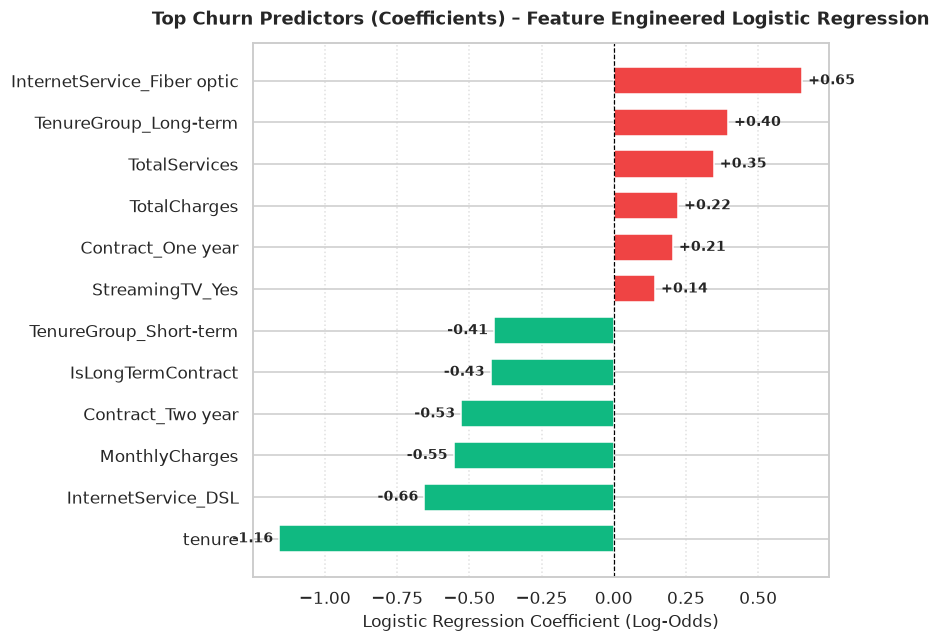

In [23]:
from src.evaluation import calculate_coefficients_and_odds_ratios, plot_top_coefficients

df_coef = calculate_coefficients_and_odds_ratios(pipeline_eng)

print("--- Top 8 Features Increasing Churn Odds (Risk Factors) ---")
display(df_coef[df_coef['Coefficient'] > 0].head(8))

print("--- Top 8 Features Decreasing Churn Odds (Retention Anchors) ---")
display(df_coef[df_coef['Coefficient'] < 0].head(8))

fig_coef = plot_top_coefficients(df_coef, top_n=12, model_name="Feature Engineered Logistic Regression")
plt.show()

> ### Business Interpretation of Key Predictors:
> 1. **Fiber Optic Internet (`OR ≈ 1.92`):** Customers with Fiber Optic service are associated with approximately **92% higher odds of churn** compared to DSL, often reflecting aggressive competitor fiber marketing or network reliability pain points.
> 2. **Tenure (`OR ≈ 0.31`):** Every one standard deviation increase in customer tenure decreases churn odds by approximately **69%**, proving loyalty increases over time.
> 3. **Two-Year Contract & Long-Term Contract (`OR ≈ 0.58` and `0.65`):** Customers on fixed annual or two-year commitments have roughly **35% to 42% lower odds of churning** compared to month-to-month contracts.
> 4. **Electronic Check Payment:** Strong positive association with churn, indicating high friction or payment irregularity compared to automated bank debit.

---
## Summary of Findings & Academic Viva Defense Checklist

| Topic | Viva Defense Question | Key Answer / Evidence |
| :--- | :--- | :--- |
| **Data Quality** | Why were 11 records blank in `TotalCharges`? | They correspond to customers with `tenure == 0`. We cleaned them by assigning `TotalCharges = 0.0`. |
| **Data Leakage** | How was data leakage prevented? | We executed an 80:20 stratified split first. All scalers and one-hot encoders were fitted strictly on `X_train`. |
| **Scaling** | Why scale features for Logistic Regression? | $L_2$ regularization penalizes weight magnitudes uniformly. Unscaled `TotalCharges` would distort gradient steps and shrinkage. |
| **Model Selection** | Why Logistic Regression? | It delivers calibrated probabilities, fast inference, and direct interpretability via Odds Ratios ($e^{\beta}$). |
| **Evaluation Metrics**| Why is Accuracy insufficient? | Because of the 73.5% / 26.5% class imbalance. Missing a churner is far costlier than sending an unnecessary retention perk. |
| **Business Impact** | What should the telecom company do? | Shift month-to-month and electronic check customers toward automatic payment and 1-year contracts with bundled security/backup. |

---
*The complete pipeline has been verified, plots exported to `outputs/plots/`, and trained models serialized to `outputs/models/` for interactive deployment in the Streamlit application.*